# 10: trening na zbiorze mieszanym `rs_video_x4k` + `rs_layers` (w pełni syntetyczny)

**Cel:** czy dołożenie zbioru warstwowego (`src/synth_layers.py`: tło + wycięte obiekty na różnych głębokościach,
tekstury ze zdjęć i proceduralne) poprawia modele, i jak modele uczone tylko na X4K radzą sobie na danych warstwowych.

**Jak:** te same modele i parametry co w dotychczasowych runach, ale `train/` = suma obu zbiorów
(`train_unet.py --data X4K LAYERS`, zmiana tylko na gałęzi `filip-layers`, `main` bez zmian).
Wybór `best.pt` i `log.csv` liczone na **val X4K** (321 próbek), więc wynik jest wprost porównywalny ze starymi runami.
Na końcu (sekcja 5) każdy model, stary i nowy, jest oceniany na **obu** zbiorach walidacyjnych.

| sekcja | run | para (stary run, tylko X4K) | epoki | czas L4 (szacunek, ~3,2× więcej danych) |
|---|---|---|---|---|
| 4a | RAFT (zamrożony) + geometria + U-Net | `*_raft_unet` (35,68 dB) | 30 | ~1,5 h |
| 4b | jw., wspólne dostrajanie RAFT + U-Net | `*_raft_unet_ft` (**35,81 dB**) | 10 | ~1,2 h |
| 4c | *(opcjonalnie)* zwykły U-Net | `*_unet_plain_long` (31,05 dB) | 200 | ~4 h |
| 4d | *(opcjonalnie)* enkoder + korelacja `corr` | `*_corr200` albo `*_corr` (80 ep., 31,06 dB) | 200 | ~6–7 h |

Uwaga do porównania: przy tej samej liczbie epok nowe runy robią ~3,2× więcej kroków (X4K 2397 + warstwowy 5387 próbek).
Jeśli nowy model wygra na val X4K, część zysku może wynikać z dłuższego treningu, nie z nowych danych
(dla 4a/4b mało prawdopodobne: stare runy nasycały się wcześniej).

**Kolejność:** SETUP → 1 → 2 → 4a → 4b → 5. Po rozłączeniu: SETUP → 1 → 2 → `train('...', resume=True)`.
Do równoległych treningów zrób kopię pliku (jeden plik = jedno jądro Colaba).

In [1]:
# === SETUP: uruchamiaj zawsze jako pierwszą komórkę ===
# Kod z GitHuba, gałąź BRANCH (tu: zmiana train_unet.py pozwalająca trenować na kilku zbiorach; main bez zmian).
REPO = 'kordiusz/RollingShutter'
BRANCH = 'filip-layers'

import os, sys, subprocess, getpass, importlib
from google.colab import drive
drive.mount('/content/drive')

TOKEN_FILE = '/content/drive/MyDrive/rs_project/.github_token'   # opcjonalnie: token zapisany na Drive
CODE = '/content/code'

def _git(*args):
    r = subprocess.run(['git', *args], capture_output=True, text=True)
    if r.returncode != 0:
        msg = (r.stderr or r.stdout).replace(token, '***') if 'token' in globals() else r.stderr
        raise RuntimeError('git ' + args[0] + ' nie powiodło się:\n' + msg)
    return r.stdout

if not os.path.exists(CODE):
    token = (open(TOKEN_FILE).read().strip() if os.path.exists(TOKEN_FILE)
             else getpass.getpass('GitHub token (fine-grained, tylko odczyt): '))
    _git('clone', '-q', '-b', BRANCH, f'https://{token}@github.com/{REPO}.git', CODE)
else:   # także gdy wcześniej sklonowano main: przełącz na BRANCH i weź najnowszą wersję
    _git('-C', CODE, 'fetch', '-q', 'origin', BRANCH)
    _git('-C', CODE, 'checkout', '-q', '-B', BRANCH, 'FETCH_HEAD')
os.chdir(CODE)
sys.path.insert(0, f'{CODE}/src')
import project_paths as P
importlib.reload(P)
P.ensure_dirs()
print(_git('log', '-1', '--format=kod: %h  %s  (%cd)  gałąź ' + BRANCH, '--date=short'))
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

Mounted at /content/drive
kod: 5c2217c  Merge branch 'main' into filip-layers  (2026-11-14)  gałąź filip-layers

NVIDIA L4, 23034 MiB


## 1. Zbiory danych (kopiowanie z Drive na dysk Colaba i rozpakowanie: `.zip` albo `.rar`)
Archiwa w `MyDrive/rs_project/datasets/`: `rs_video_x4k.zip` i `rs_layers.rar`. Archiwum musi zawierać folder
z podfolderami `train/` i `val/`. Rozpakowanie warstwowego (~3 GB) trwa kilka minut; drugi raz w tej samej sesji się nie wykonuje.

In [2]:
import os, glob, shutil, subprocess

def find_archive(name):
    for d in (P.DATASETS, P.MYDRIVE):
        for ext in ('zip', 'rar'):
            p = d / f'{name}.{ext}'
            if p.exists():
                return p
    return None

def prepare(name):
    # rozpakowuje <name>.zip / <name>.rar do /content/unz_<name>, zwraca folder z train/ i val/
    z = find_archive(name)
    assert z, f'Brak {name}.zip ani {name}.rar w {P.DATASETS}'
    unz = f'/content/unz_{name}'
    done = f'{unz}/.rozpakowane'          # znacznik: rozpakowanie skończyło się bez błędu
    if not os.path.exists(done):
        shutil.rmtree(unz, ignore_errors=True)
        os.makedirs(unz)
        local = f'/content/{z.name}'
        # najpierw kopia na dysk Colaba: czytanie archiwum wprost z Drive potrafi się urwać
        print(f'kopiuję {z} ({os.path.getsize(z) / 1e9:.2f} GB) na dysk Colaba ...')
        subprocess.run(['cp', str(z), local], check=True)
        print('rozpakowuję ...')
        if z.suffix == '.zip':
            t = subprocess.run(['unzip', '-tq', local], capture_output=True, text=True)
            assert t.returncode == 0, 'Archiwum uszkodzone - wgraj je na Drive ponownie:\n' + (t.stdout + t.stderr)[-1500:]
            subprocess.run(['unzip', '-q', local, '-d', unz], check=True)
        else:
            if not shutil.which('unrar'):
                subprocess.run('apt-get -qq update && apt-get -qq install -y unrar', shell=True, check=True,
                               stdout=subprocess.DEVNULL)
            t = subprocess.run(['unrar', 'x', '-idq', '-o+', local, unz + '/'], capture_output=True, text=True)
            assert t.returncode == 0, 'unrar: błąd (archiwum uszkodzone?):\n' + (t.stdout + t.stderr)[-1500:]
        os.remove(local)
        open(done, 'w').close()
    data = next(os.path.dirname(p) for p in sorted(glob.glob(f'{unz}/**/train', recursive=True)))
    assert os.path.isdir(f'{data}/val'), f'brak {data}/val - usuń {unz} i uruchom komórkę ponownie'
    print(f'{name}: {data} | {len(os.listdir(f"{data}/train"))} train / {len(os.listdir(f"{data}/val"))} val')
    return data

DATA_X4K = prepare('rs_video_x4k')
DATA_LAYERS = prepare('rs_layers')
VALS = {'x4k': DATA_X4K, 'layers': DATA_LAYERS}
WORKERS = min(8, os.cpu_count())

kopiuję /content/drive/MyDrive/rs_project/datasets/rs_video_x4k.zip (1.23 GB) na dysk Colaba ...
rozpakowuję ...
rs_video_x4k: /content/unz_rs_video_x4k/rs_video_x4k | 2397 train / 321 val
kopiuję /content/drive/MyDrive/rs_project/datasets/rs_layers.rar (3.05 GB) na dysk Colaba ...
rozpakowuję ...
rs_layers: /content/unz_rs_layers/rs_layers | 5387 train / 613 val


## 2. Nazwy runów i parametry
Nowe runy mają końcówkę `_mix`, więc `P.find_run('raft_unet')` w innych notatnikach nadal znajduje stare runy (tylko X4K).
Przy wznawianiu innego dnia wpisz w `DAY` datę istniejących folderów z `runs/`.

In [3]:
from datetime import date
from IPython.display import Image, display
DAY = str(date.today())          # np. '2026-11-12' przy wznawianiu
TRAIN_DATA = f'"{DATA_X4K}" "{DATA_LAYERS}"'    # pierwszy = zbiór walidacyjny w trakcie treningu (best.pt)
RAFT_CKPT = P.find_run('raft_geom_v2') or P.find_run('raft_geom')
print('RAFT dla 4a:', RAFT_CKPT or 'brak dostrojonego - gotowe wagi RAFT')

RUNS = {job: f'{DAY}_{job}_mix' for job in ('raft_unet', 'raft_unet_ft', 'unet_plain', 'corr')}
JOBS = {   # nazwa: (argumenty train_unet.py) - te same co w parze z X4K
    'raft_unet':    '--mode refine ' + (f'--raft-ckpt "{RAFT_CKPT}" ' if RAFT_CKPT else '') + '--epochs 30 --bs 8 --lr 3e-4',
    'raft_unet_ft': f'--mode refine --init "{P.RUNS / RUNS["raft_unet"] / "best.pt"}" --raft-lr 1e-5 --lr 1e-4 --epochs 10 --bs 8',
    'unet_plain':   '--mode plain --epochs 200 --bs 16 --lr 3e-4',
    'corr':         '--mode corr --epochs 200 --bs 16 --lr 3e-4',
}
PAIRS = {   # stary run (tylko X4K) do porównania
    'raft_unet': ['raft_unet'], 'raft_unet_ft': ['raft_unet_ft'],
    'unet_plain': ['unet_plain_long'], 'corr': ['corr200', 'corr'],
}

def train(job, resume=False):
    missing = [v for v in ('P', 'DATA_X4K', 'DATA_LAYERS', 'WORKERS') if v not in globals()]
    if missing:
        raise RuntimeError(f'brak {missing}: najpierw uruchom SETUP i komórkę 1 w tej sesji')
    run = RUNS[job]
    res = f' --resume "{P.RUNS / run / "last.pt"}"' if resume else ''
    cmd = (f'python src/train_unet.py --data {TRAIN_DATA} {JOBS[job]} --workers {WORKERS} '
           f'--out "{P.RUNS}" --name {run}{res}')
    print(cmd)
    get_ipython().system(cmd)
    prev = sorted((P.RUNS / run).glob('preview_ep*.png'))
    if prev:
        print(prev[-1]); display(Image(str(prev[-1])))
print(RUNS)

RAFT dla 4a: /content/drive/MyDrive/rs_project/runs/2026-11-03_raft_geom_v2/best.pt
{'raft_unet': '2026-11-15_raft_unet_mix', 'raft_unet_ft': '2026-11-15_raft_unet_ft_mix', 'unet_plain': '2026-11-15_unet_plain_mix', 'corr': '2026-11-15_corr_mix'}


## 3. (opcjonalnie) Szybki test, czy wszystko działa (~1 min)
Kilka próbek z każdego zbioru, 1 epoka, folder `runs/_test_mix` (można go potem usunąć).

In [ ]:
!python src/train_unet.py --data {TRAIN_DATA} --mode plain --epochs 1 --bs 4 --limit 16 --workers {WORKERS} --out "{P.RUNS}" --name _test_mix

## 4a. RAFT (zamrożony) + geometria + U-Net, 30 epok (~1,5 h L4)
RAFT z `*_raft_geom_v2` (dostrojony na X4K). W logu `RAFT+geom` = sam RAFT + geometria, `from B` = ile obrazu bierze z kamery B.

python src/train_unet.py --data "/content/unz_rs_video_x4k/rs_video_x4k" "/content/unz_rs_layers/rs_layers" --mode refine --raft-ckpt "/content/drive/MyDrive/rs_project/runs/2026-11-03_raft_geom_v2/best.pt" --epochs 30 --bs 8 --lr 3e-4 --workers 8 --out "/content/drive/MyDrive/rs_project/runs" --name 2026-11-15_raft_unet_mix
device: cuda
2026-11-15_raft_unet_mix (refine): 7.98 M params (2.73 M trainable), 7784 train / 321 val samples
before training: val PSNR 34.40 dB (input 26.43, RAFT+geometry 34.36)
ep   1/30 loss 0.0306 | val PSNR 34.82 dB (RAFT+geom 34.36, input 26.43) SSIM 0.9482 | full image 34.32 dB | from B 18.4% | 170s
ep   2/30 loss 0.0288 | val PSNR 35.07 dB (RAFT+geom 34.36, input 26.43) SSIM 0.9509 | full image 34.58 dB | from B 26.1% | 170s
ep   3/30 loss 0.0293 | val PSNR 35.17 dB (RAFT+geom 34.36, input 26.43) SSIM 0.9517 | full image 34.70 dB | from B 27.1% | SKIPPED 1/973 steps | 171s
ep   4/30 loss 0.0277 | val PSNR 35.27 dB (RAFT+geom 34.36, input 26.43) SSIM 0.951

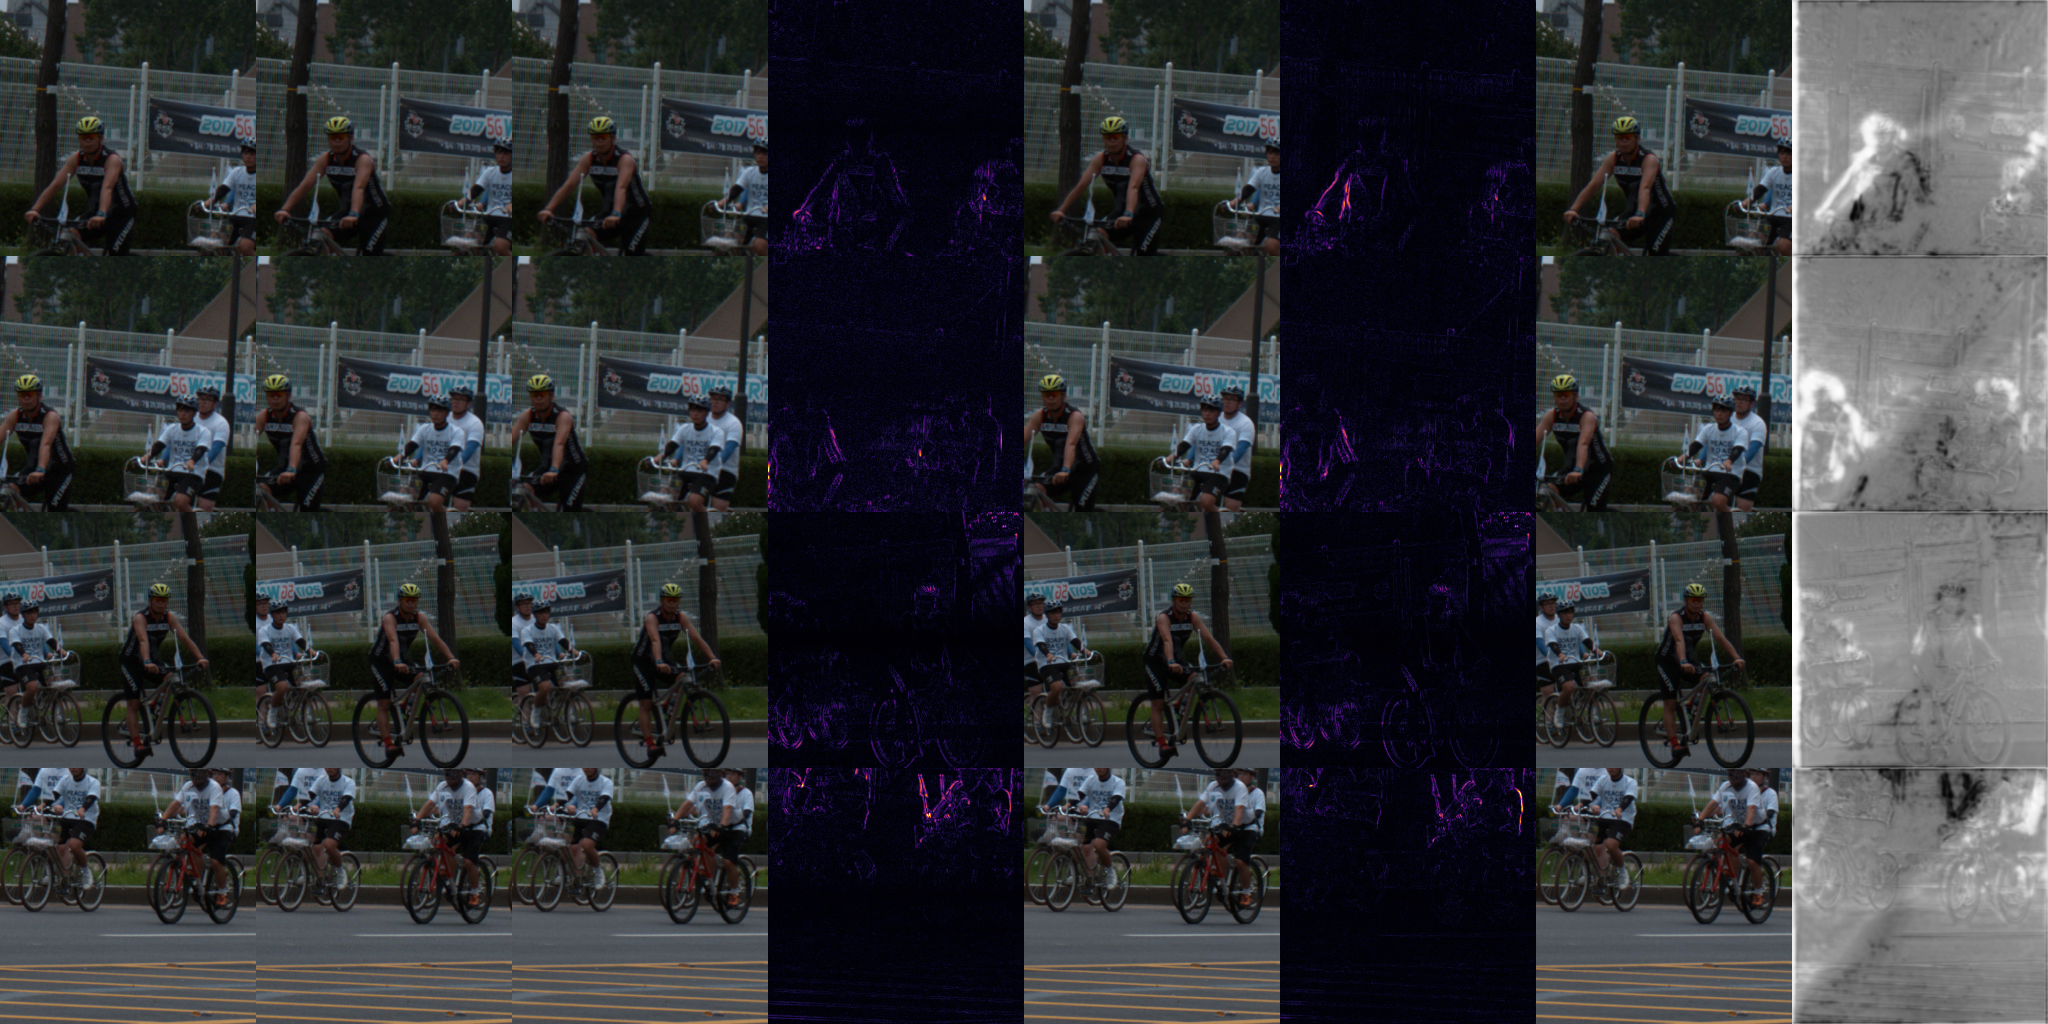

In [4]:
train('raft_unet')

## 4b. Wspólne dostrajanie RAFT + U-Net, 10 epok (~1,2 h L4)
Start z `best.pt` z 4a. Tu RAFT po raz pierwszy widzi dane warstwowe.

python src/train_unet.py --data "/content/unz_rs_video_x4k/rs_video_x4k" "/content/unz_rs_layers/rs_layers" --mode refine --init "/content/drive/MyDrive/rs_project/runs/2026-11-15_raft_unet_mix/best.pt" --raft-lr 1e-5 --lr 1e-4 --epochs 10 --bs 8 --workers 8 --out "/content/drive/MyDrive/rs_project/runs" --name 2026-11-15_raft_unet_ft_mix
device: cuda
Downloading: "https://download.pytorch.org/models/raft_large_C_T_SKHT_V2-ff5fadd5.pth" to /root/.cache/torch/hub/checkpoints/raft_large_C_T_SKHT_V2-ff5fadd5.pth
100% 20.1M/20.1M [00:00<00:00, 218MB/s]
2026-11-15_raft_unet_ft_mix (refine): 7.98 M params (7.98 M trainable), 7784 train / 321 val samples
before training: val PSNR 35.75 dB (input 26.43, RAFT+geometry 34.36)
ep   1/10 loss 0.0247 | val PSNR 35.74 dB (RAFT+geom 34.37, input 26.43) SSIM 0.9550 | full image 35.32 dB | from B 40.9% | 401s
ep   2/10 loss 0.0244 | val PSNR 35.78 dB (RAFT+geom 34.34, input 26.43) SSIM 0.9548 | full image 35.35 dB | from B 40.7% | 400s
ep   3/10 loss 0

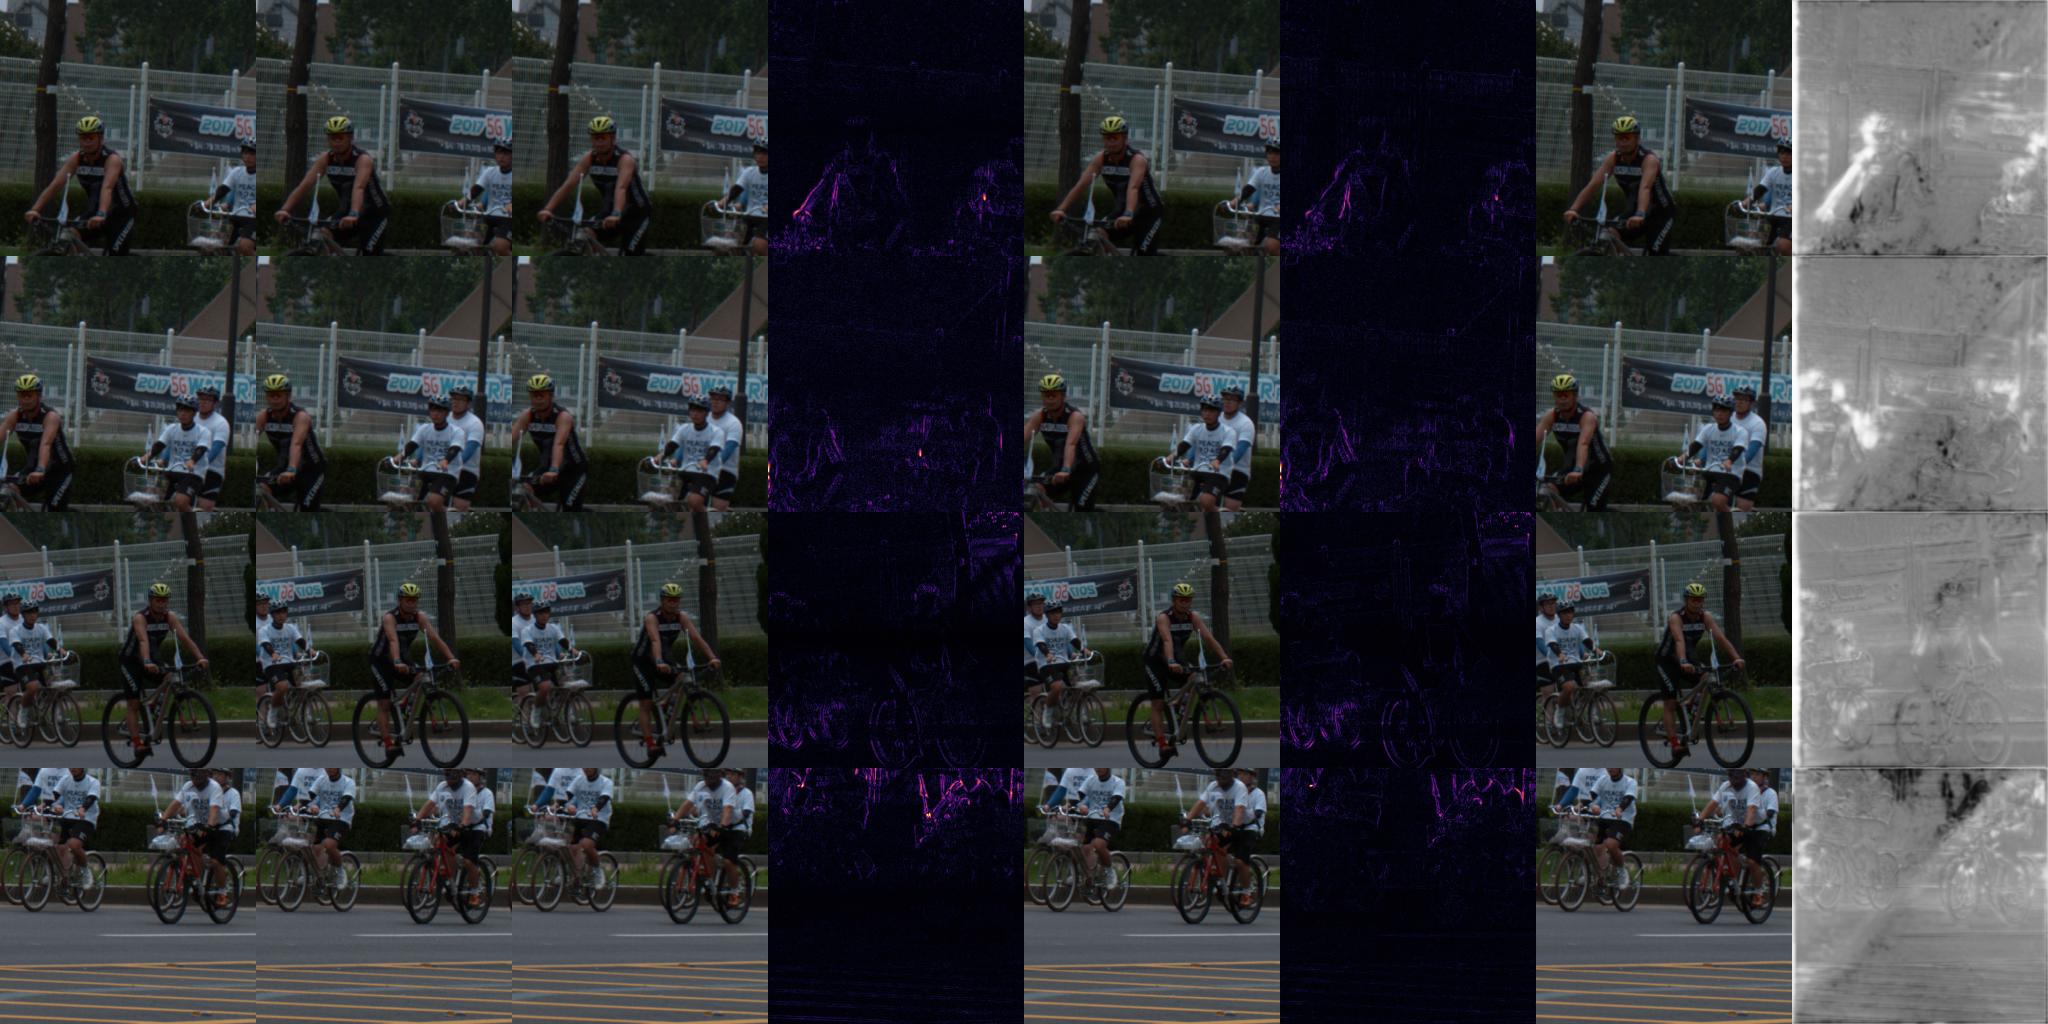

In [5]:
train('raft_unet_ft')

## 4c. (opcjonalnie) Zwykły U-Net, 200 epok (~4 h L4)

In [ ]:
train('unet_plain')

## 4d. (opcjonalnie) `corr`, 200 epok (~6–7 h L4)

In [ ]:
train('corr')

python src/train_unet.py --data "/content/unz_rs_video_x4k/rs_video_x4k" "/content/unz_rs_layers/rs_layers" --mode corr --epochs 200 --bs 16 --lr 3e-4 --workers 8 --out "/content/drive/MyDrive/rs_project/runs" --name 2026-11-15_corr_mix
device: cuda
2026-11-15_corr_mix (corr): 6.24 M params (6.24 M trainable), 7784 train / 321 val samples
before training: val PSNR 26.35 dB (input 26.35)
ep   1/200 loss 0.0769 | val PSNR 26.34 dB (input 26.35) SSIM 0.7973 | full image 26.34 dB | 111s
ep   2/200 loss 0.0746 | val PSNR 25.85 dB (input 26.35) SSIM 0.7910 | full image 25.85 dB | 109s
ep   3/200 loss 0.0718 | val PSNR 25.41 dB (input 26.35) SSIM 0.7864 | full image 25.41 dB | 109s
ep   4/200 loss 0.0690 | val PSNR 26.32 dB (input 26.35) SSIM 0.8022 | full image 26.32 dB | 109s
ep   5/200 loss 0.0654 | val PSNR 27.14 dB (input 26.35) SSIM 0.8146 | full image 27.14 dB | 109s
ep   6/200 loss 0.0607 | val PSNR 27.91 dB (input 26.35) SSIM 0.8289 | full image 27.91 dB | 109s
ep   7/200 loss 0.0571

## 5. Porównanie: każdy model na obu zbiorach walidacyjnych
Stare runy (tylko X4K) i nowe (`_mix`), wszystkie liczone tym samym `--eval` na val X4K i val warstwowym.
Wyniki zapisują się w `MyDrive/rs_project/results/porownanie_mix/` (foldery starych runów nie są ruszane);
policzone wcześniej nie są liczone ponownie (`REDO = True`, żeby wymusić).
Na zbiorze warstwowym dodatkowo podział na tekstury: zdjęcia / proceduralne.

In [ ]:
import json, pandas as pd
REDO = False
OUT = P.RESULTS / 'porownanie_mix'
OUT.mkdir(parents=True, exist_ok=True)

def first_run(names):
    for n in names:
        ck = P.find_run(n)
        if ck:
            return ck
    return None

models = []   # (model, trenowany na, checkpoint)
for job, run in RUNS.items():
    old = first_run(PAIRS[job])
    if old:
        models.append((job, 'X4K', old))
    new = P.RUNS / run / 'best.pt'
    if new.exists():
        models.append((job, 'X4K + layers', new))

textures = {}  # próbka val warstwowego -> 'photos' / 'procedural'
for d in sorted(glob.glob(f'{DATA_LAYERS}/val/*/meta.json')):
    textures[os.path.basename(os.path.dirname(d))] = json.load(open(d)).get('textures', '?')

rows, inp = [], {}
for model, trained, ck in models:
    run = ck.parent.name
    r = {'model': model, 'trening': trained, 'run': run}
    for vname, vdata in VALS.items():
        ej, ps = OUT / f'{run}__{vname}.json', OUT / f'{run}__{vname}.csv'
        if REDO or not ej.exists():
            print('eval', run, 'na', vname, '...')
            !python src/train_unet.py --data "{vdata}" --eval "{ck}" --eval-json "{ej}" --per-sample "{ps}" --bs 8 --workers {WORKERS} > /dev/null
        m = json.load(open(ej))['metrics']
        r[f'{vname} psnr'], r[f'{vname} psnr_full'], r[f'{vname} ssim'] = m['psnr'], m['psnr_full'], m['ssim']
        if 'psnr_geom' in m:
            r[f'{vname} RAFT+geom'] = m['psnr_geom']
        inp[vname] = (m['psnr_in'], m['psnr_full_in'], m['ssim_in'])
        if vname == 'layers':
            df = pd.read_csv(ps, dtype={'sample': str})
            df['tex'] = df['sample'].map(textures)
            for tex, g in df.groupby('tex'):
                r[f'layers psnr ({tex})'] = g['psnr'].mean()
    rows.append(r)

base = {'model': 'bez korekcji', 'trening': '-', 'run': '-'}
for vname, (p, pf, s) in inp.items():
    base.update({f'{vname} psnr': p, f'{vname} psnr_full': pf, f'{vname} ssim': s})
if rows:   # wejście bez korekcji w podziale na tekstury (takie samo dla każdego modelu)
    df = pd.read_csv(OUT / f'{rows[0]["run"]}__layers.csv', dtype={'sample': str})
    df['tex'] = df['sample'].map(textures)
    for tex, g in df.groupby('tex'):
        base[f'layers psnr ({tex})'] = g['psnr_in'].mean()
tab = pd.DataFrame([base] + rows).set_index(['model', 'trening'])
display(tab.round(2))
tab.to_csv(OUT / 'tabela.csv')
print('psnr = obszar widoczny w A, psnr_full = cały obraz; val x4k = 321 próbek, val layers =', len(textures))
print('zapisano', OUT / 'tabela.csv')

## 6. Po treningu
Dopisz do `experiments/README.md` (na tej gałęzi): zbiór `rs_layers` w tabeli zbiorów (parametry z `config.json`,
5387 train / 613 val) i wiersze nowych runów z tabeli z sekcji 5 (val X4K i val warstwowy osobno). Commit notatnika z wynikami.